# Operações convolucionais

Nesta primeira parte vamos **ver** o que acontece dentro de uma CNN:
como um *kernel* percorre a imagem e realça padrões (convolução),
o efeito da ativação **ReLU** e a redução de resolução do **max pooling**.

## Setup

In [ ]:
import os

# Silencia os avisos do TensorFlow (deve vir antes do import)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import matplotlib.pyplot as plt
import keras
from scipy.signal import convolve2d
from skimage.data import astronaut

## Funções auxiliares

Três funções dão conta de toda a aula: uma para exibir imagens, uma para
convoluir e uma para montar a figura comparativa.

In [ ]:
def plot_images(images, titles=None, scale=4):
    """Exibe uma lista de imagens lado a lado, sem eixos."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(scale * n, scale))
    axes = np.atleast_1d(axes)  # garante iterável quando há uma única imagem

    for i, (ax, img) in enumerate(zip(axes, images)):
        ax.imshow(img, cmap="gray")
        ax.axis("off")
        if titles is not None:
            ax.set_title(titles[i], fontsize=13)

    plt.tight_layout()
    plt.show()


def convolve(image, kernel, relu=False):
    """Convolui uma imagem em escala de cinza (H, W) ou RGB (H, W, 3).

    Em RGB, cada canal é convoluído e os resultados são somados, produzindo
    um único feature map (H, W), exatamente o que uma CNN faz.
    Com relu=True, os valores negativos são zerados.
    Retorna uint8 (0-255) apenas para visualização.

    """
    image = np.asarray(image, dtype=np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)

    if image.ndim == 3:  # RGB: aplica canal a canal e soma
        feature_map = sum(
            convolve2d(image[:, :, c], kernel, mode="same", boundary="symm")
            for c in range(image.shape[-1])
        )
    else:  # escala de cinza
        feature_map = convolve2d(image, kernel, mode="same", boundary="symm")

    if relu:
        feature_map = np.maximum(0, feature_map)

    # Normaliza para a faixa 0-255
    lo, hi = feature_map.min(), feature_map.max()
    if hi == lo:
        return np.zeros(feature_map.shape, dtype=np.uint8)

    feature_map = (feature_map - lo) / (hi - lo)
    return np.rint(feature_map * 255).astype(np.uint8)


def plot_conv(image, kernel, outputs, kernel_name=""):
    """Plota: imagem original | kernel | uma coluna para cada saída.

    outputs: dicionário {título: imagem}, ex. {"Linear": lin, "ReLU": rel}
    """
    K = kernel.shape[0]
    n = 2 + len(outputs)  # original + kernel + saídas
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5.5))

    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Entrada", fontsize=14)
    axes[0].axis("off")

    # Mostra o kernel como imagem, com os valores escritos sobre as células
    axes[1].imshow(kernel, cmap="gray")
    axes[1].set_title(f"Kernel {K}x{K}\n{kernel_name}", fontsize=14)
    for i in range(K):
        for j in range(K):
            axes[1].text(j, i, f"{kernel[i, j]:.0f}", ha="center", va="center",
                         color="red", fontsize=13, weight="bold")
    axes[1].set_xticks([])
    axes[1].set_yticks([])

    for ax, (title, output) in zip(axes[2:], outputs.items()):
        ax.imshow(output, cmap="gray")
        ax.set_title(title, fontsize=14)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Dados

Usamos o MNIST: 60 mil imagens 28x28 de dígitos manuscritos, em escala de cinza.

In [ ]:
(x_train, y_train), (_, _) = keras.datasets.mnist.load_data()

print("Shape do conjunto de treino:", x_train.shape)

In [ ]:
# Amostra aleatória de 5 dígitos
idx = np.random.choice(len(x_train), 5, replace=False)
plot_images(x_train[idx])

In [ ]:
# Escolhe uma imagem para usar nas demonstrações
idx = np.random.choice(len(x_train))
image, label = x_train[idx], y_train[idx]

plot_images([image], titles=[f"Dígito: {label}"])

## Kernels

Um kernel é apenas uma matriz pequena de pesos. Numa CNN real esses valores são
**aprendidos**; aqui eles são definidos à mão para que o efeito de cada um fique visível.

Repare no formato de cada matriz: ele antecipa o efeito. A convolução **carimba** o
kernel sobre cada ponto claro da imagem, então o realce sai com a mesma orientação
dos pesos: `[1, 0, -1]` (positivo à esquerda) realça o lado esquerdo dos traços,
e o kernel oposto realça o direito.

Dois grupos aparecem abaixo:

- **Derivativos** (Prewitt, Sobel, diagonal): somam zero e respondem a *variações* de
  intensidade, ou seja, bordas. O Sobel é o Prewitt com peso maior na linha central,
  o que lhe dá menos sensibilidade a ruído.
- **Suavização** (box blur, gaussiano): todos os pesos são positivos, então cada pixel
  vira uma média da vizinhança: a saída perde detalhe em vez de realçá-lo. O gaussiano
  pondera o centro mais que as bordas da janela.

In [ ]:
KERNELS_3X3 = {
    "Prewitt X": np.array([
        [1, 0, -1],
        [1, 0, -1],
        [1, 0, -1],
    ]),
    "Prewitt -X": np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1],
    ]),
    "Prewitt Y": np.array([
        [ 1,  1,  1],
        [ 0,  0,  0],
        [-1, -1, -1],
    ]),
    "Sobel X": np.array([
        [1, 0, -1],
        [2, 0, -2],
        [1, 0, -1],
    ]),
    "Sobel Y": np.array([
        [ 1,  2,  1],
        [ 0,  0,  0],
        [-1, -2, -1],
    ]),
    "Diagonal": np.array([
        [-1, 0,  1],
        [ 0, 1,  0],
        [ 1, 0, -1],
    ]),
    "Sharpen": np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0],
    ]),
    "Box blur": np.array([
        [1, 1, 1],
        [1, 1, 1],
        [1, 1, 1],
    ]),
}

## Convolução em escala de cinza

Para cada kernel comparamos a saída **linear** (só a convolução) com a saída após a
**ReLU**, que zera todos os valores negativos.

In [ ]:
for name, kernel in KERNELS_3X3.items():
    outputs = {
        "Convolução linear": convolve(image, kernel),
        "Convolução + ReLU": convolve(image, kernel, relu=True),
    }
    plot_conv(image, kernel, outputs, kernel_name=name)

## Convolução em imagem RGB

Numa imagem colorida o kernel é aplicado a **cada canal** e os três resultados são
**somados**: três canais entram, um único feature map sai.

In [ ]:
# Imagem RGB de exemplo que acompanha o scikit-image
image_rgb = astronaut()

print("Shape da imagem RGB:", image_rgb.shape)
plot_images([image_rgb], scale=5)

In [ ]:
KERNELS_5X5 = {
    "Prewitt X": np.array([
        [1, 1, 0, -1, -1],
        [1, 1, 0, -1, -1],
        [1, 1, 0, -1, -1],
        [1, 1, 0, -1, -1],
        [1, 1, 0, -1, -1],
    ]),
    "Prewitt -X": np.array([
        [-1, -1, 0, 1, 1],
        [-1, -1, 0, 1, 1],
        [-1, -1, 0, 1, 1],
        [-1, -1, 0, 1, 1],
        [-1, -1, 0, 1, 1],
    ]),
    "Sobel X": np.array([
        [2, 1, 0, -1, -2],
        [3, 2, 0, -2, -3],
        [4, 3, 0, -3, -4],
        [3, 2, 0, -2, -3],
        [2, 1, 0, -1, -2],
    ]),
    "Diagonal": np.array([
        [-1, -1, 0,  0,  1],
        [-1,  0, 0,  1,  0],
        [ 0,  0, 1,  0,  0],
        [ 0,  1, 0,  0, -1],
        [ 1,  0, 0, -1, -1],
    ]),
    "Sharpen": np.array([
        [ 0,  0, -1,  0,  0],
        [ 0, -1,  3, -1,  0],
        [-1,  3,  5,  3, -1],
        [ 0, -1,  3, -1,  0],
        [ 0,  0, -1,  0,  0],
    ]),
    "Gaussian blur": np.array([
        [1,  4,  6,  4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1,  4,  6,  4, 1],
    ]),
}

In [ ]:
for name, kernel in KERNELS_5X5.items():
    outputs = {
        "Convolução linear": convolve(image_rgb, kernel),
        "Convolução + ReLU": convolve(image_rgb, kernel, relu=True),
    }
    plot_conv(image_rgb, kernel, outputs, kernel_name=name)

### Observação: convolução ou correlação cruzada?

A convolução matemática **gira o kernel em 180°** antes do sweep. É isso que faz o
filtro se comportar como um "carimbo": um ponto isolado na entrada deposita na saída uma
cópia fiel do kernel.

Duas ressalvas:

- O carimbo sai fiel quando o objeto é **claro sobre fundo escuro** (o caso do MNIST).
  Se o objeto for escuro sobre fundo claro, ele entra com peso negativo e o realce troca de lado.
- A camada `Conv2D` de redes neurais, na prática, **não** gira o kernel: ela faz *correlação cruzada*.
  Para a rede tanto faz! Os pesos são aprendidos, e ela aprende a versão girada se precisar; a que for melhor para a tarefa.
  A diferença só aparece quando escrevemos o kernel manualmente, como aqui.

## MaxPooling2D

O max pooling desliza uma janela (por padrão 2x2, com passo 2) e mantém apenas o
**maior valor** de cada região: a resolução cai pela metade e o que é forte permanece.

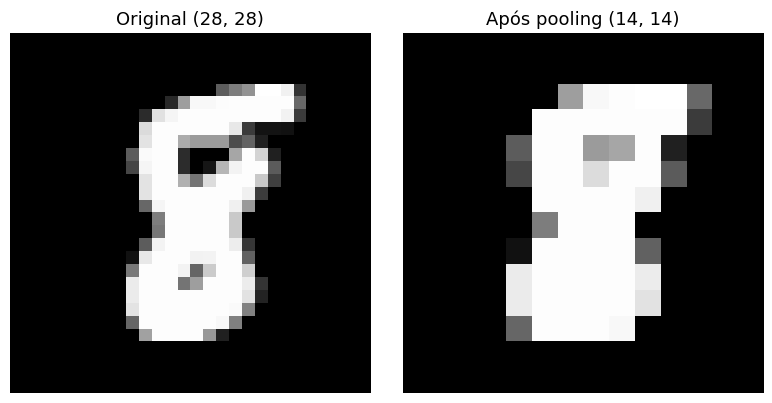

In [23]:
pool = keras.layers.MaxPooling2D()  # padrão: janela 2x2, passo 2

# layer espera um batch de imagens no formato (N, altura, largura, canais)
batch = image[None, ..., None] # (28, 28) => (1, 28, 28, 1)
pooled = pool(batch)[0, ..., 0].numpy().astype("uint8")

plot_images([image, pooled],
            titles=[f"Original {image.shape}", f"Após pooling {pooled.shape}"])

## Juntando tudo: convolução → ReLU → pooling

Esta é a sequência que se repete dentro de uma CNN, camada após camada.

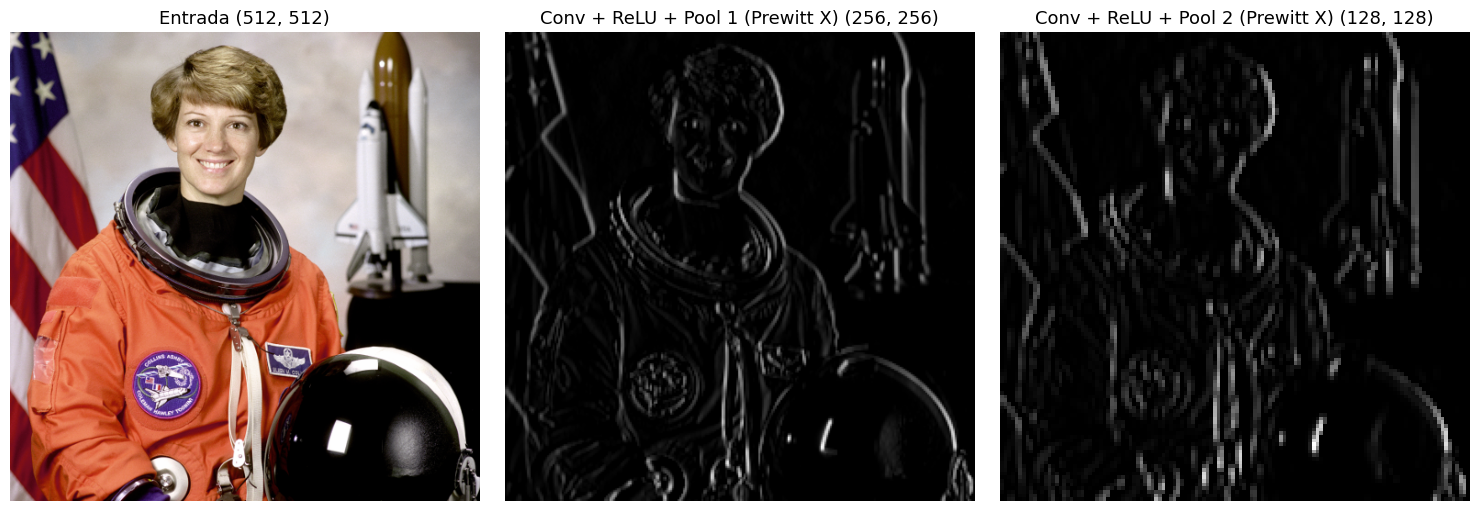

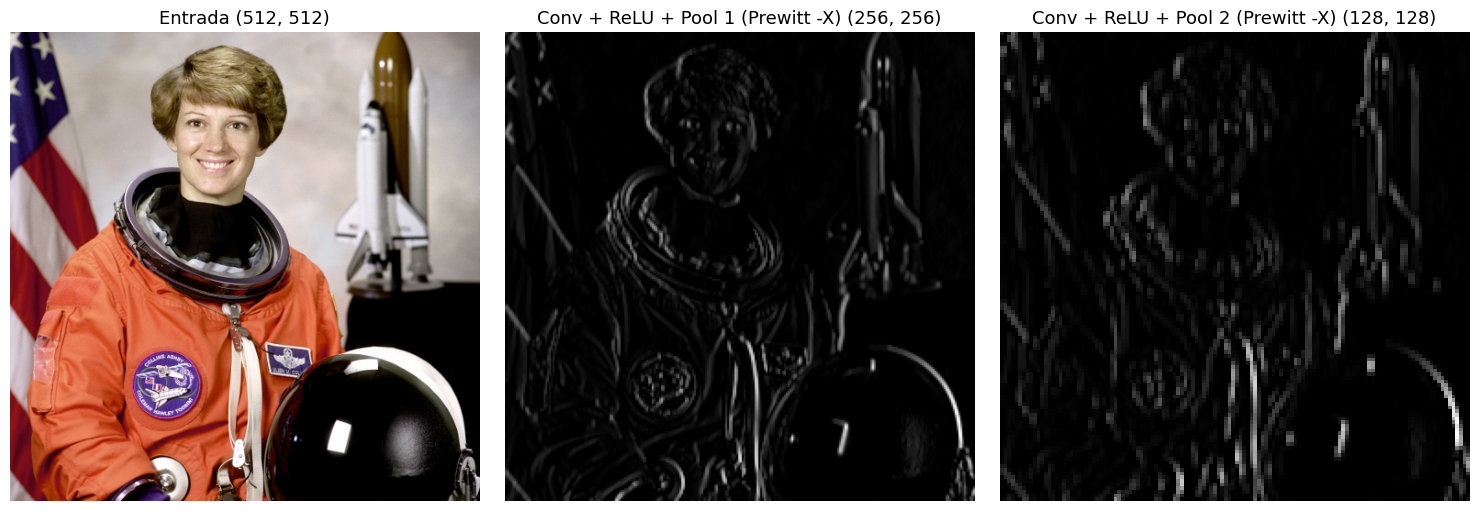

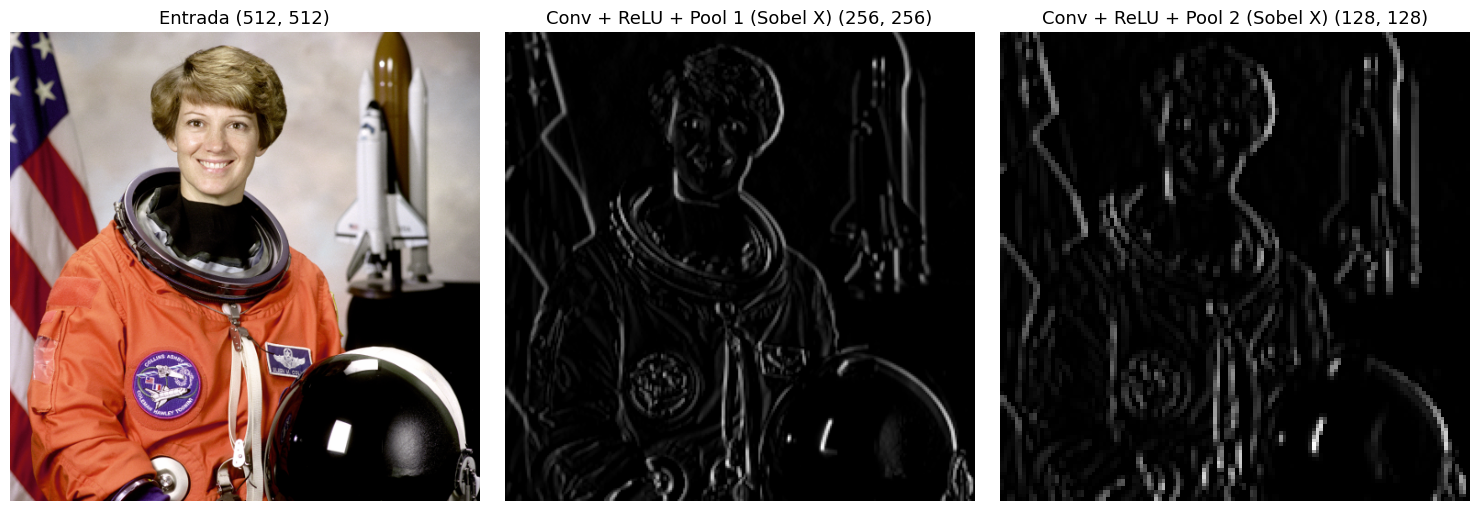

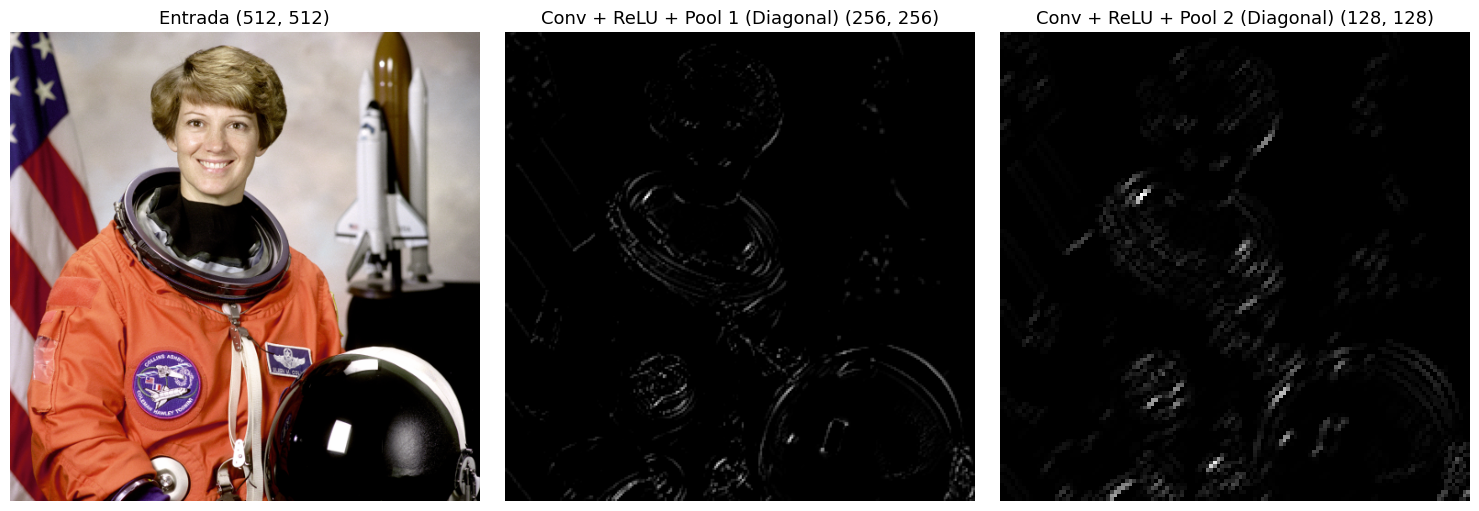

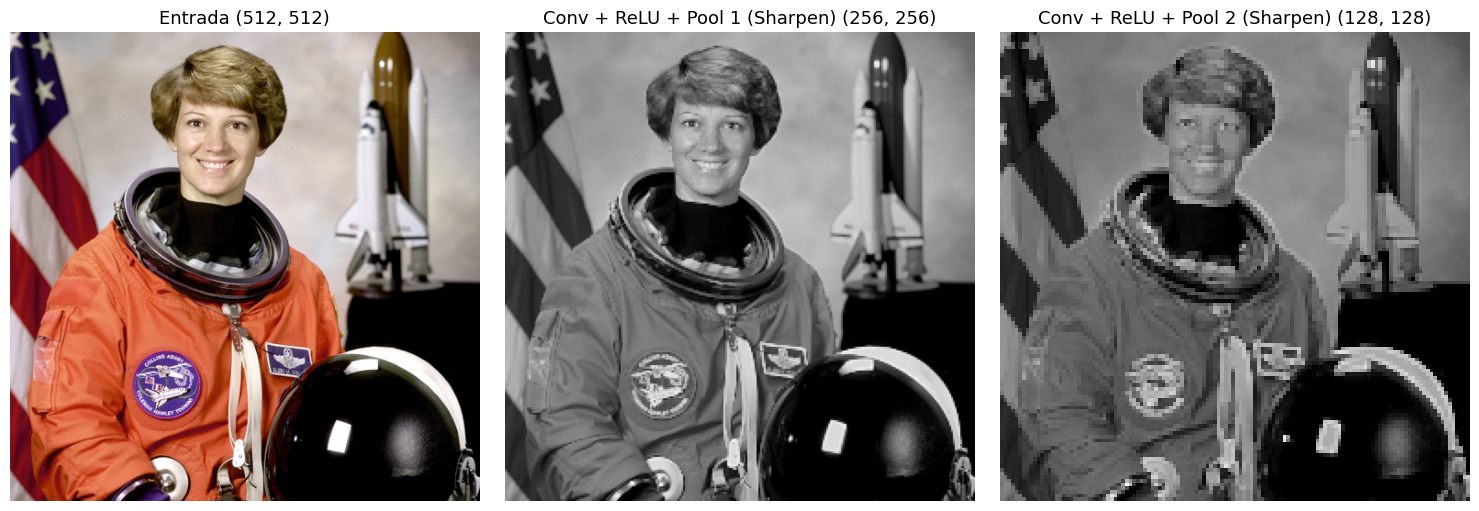

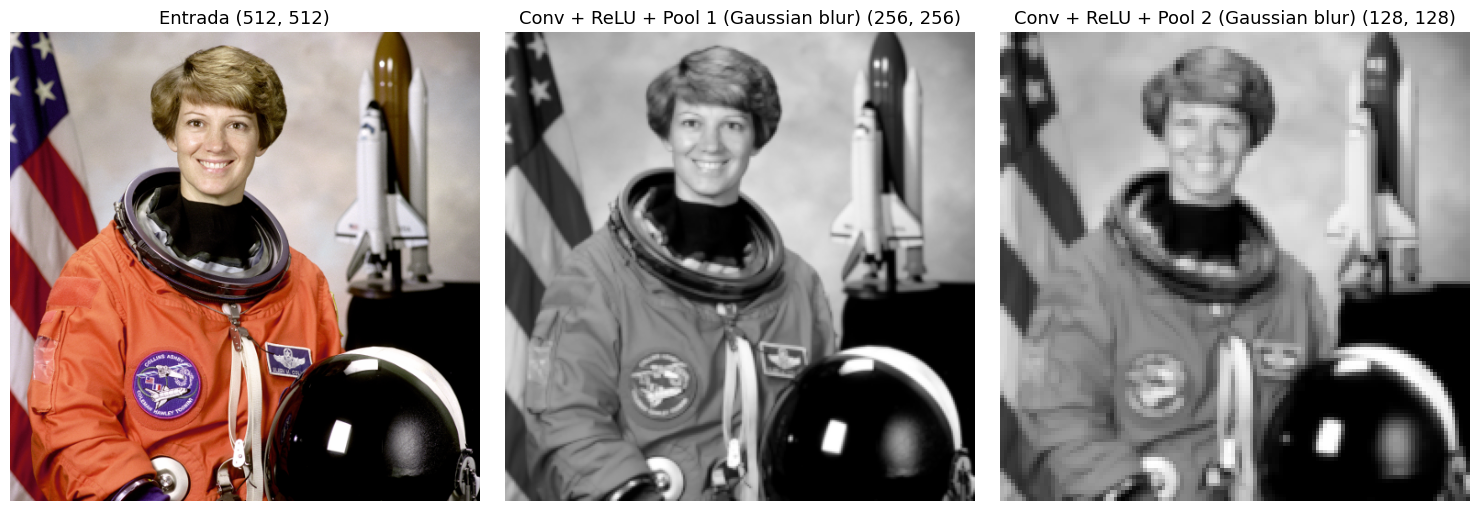

In [24]:
for name, kernel in KERNELS_5X5.items():
    # conv 1 
    feature_map_1 = convolve(image_rgb, kernel, relu=True)
    size_1 = feature_map_1.shape[0]

    # pooling 1
    batch_1 = feature_map_1[None, ..., None]
    pooled_1 = pool(batch_1)[0, ..., 0].numpy()
    size_2 = pooled_1.shape[0]

    # conv 2 -> pooling 2
    feature_map_2 = convolve(pooled_1, kernel, relu=True)
    batch_2 = feature_map_2[None, ..., None]
    pooled_2 = pool(batch_2)[0, ..., 0].numpy().astype("uint8")
    size_3 = pooled_2.shape[0]

    plot_images([image_rgb, pooled_1, pooled_2], scale=5,
                titles=[
                    f"Entrada {(size_1, size_1)}",
                    f"Conv + ReLU + Pool 1 ({name}) {(size_2, size_2)}",
                    f"Conv + ReLU + Pool 2 ({name}) {(size_3, size_3)}"
                ])